### PyTorch Workflow Fundamentals
The essence of machine learning and deep learning is to take some data from the past, build an algorithm (like a neural network) to discover patterns in it and use the discovered patterns to predict the future.


And we see if we can build a PyTorch model that learns the pattern of the straight line and matches it.

<img src="https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01_a_pytorch_workflow.png" width=900 alt="a pytorch workflow flowchat"/>


| **Topic** | **Contents** |
| ----- | ----- |
| **1. Getting data ready** | Data can be almost anything but to get started we're going to create a simple straight line |
| **2. Building a model** | Here we'll create a model to learn patterns in the data, we'll also choose a **loss function**, **optimizer** and build a **training loop**. | 
| **3. Fitting the model to data (training)** | We've got data and a model, now let's let the model (try to) find patterns in the (**training**) data. |
| **4. Making predictions and evaluating a model (inference)** | Our model's found patterns in the data, let's compare its findings to the actual (**testing**) data. |
| **5. Saving and loading a model** | You may want to use your model elsewhere, or come back to it later, here we'll cover that. |
| **6. Putting it all together** | Let's take all of the above and combine it. |

In [121]:
import torch
from torch import nn # contains all pytorch's building blocks for neural networks
import matplotlib.pyplot as plt

torch.__version__

'2.13.0+cpu'

### Data Preparing and loading

![machine learning is a game of two parts: 1. turn your data into a representative set of numbers and 2. build or pick a model to learn the representation as best as possible](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01-machine-learning-a-game-of-two-parts.png)

Machine Learning is a game of two parts: 

1. turn your data into a representative set of numbers 
2. build or pick a model to learn the representation as best as possible

We'll use [linear regression](https://en.wikipedia.org/wiki/Linear_regression) to create the data with known **parameters** (things that can be learned by a model) and then we'll use PyTorch to see if we can build model to estimate these parameters using [**gradient descent**](https://en.wikipedia.org/wiki/Gradient_descent).


In [122]:
#create known parameters
weight=0.7
bias=0.3

#Create data
start=0
end=1
step=0.02
X=torch.arange(start,end,step).unsqueeze(dim=1)
y=weight*X+bias
X[:5],y[:5],X.shape

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560]]),
 torch.Size([50, 1]))

#### Split data into training and test sets

| Split | Purpose | Amount of total data | How often is it used? |
| ----- | ----- | ----- | ----- |
| **Training set** | The model learns from this data (like the course materials you study during the semester). | ~60-80% | Always |
| **Validation set** | The model gets tuned on this data (like the practice exam you take before the final exam). | ~10-20% | Often but not always |
| **Testing set** | The model gets evaluated on this data to test what it has learned (like the final exam you take at the end of the semester). | ~10-20% | Always |

In [123]:
#create train test split
train_split=int(0.8*len(X)) #80% of data
X_train,y_train=X[:train_split],y[:train_split]
X_test,y_test=X[train_split:],y[train_split:]
len(X_train),len(y_train),len(X_test),len(y_test)

(40, 40, 10, 10)

In [124]:
def plot_predictions(train_data=X_train,train_labels=y_train,test_data=X_test,test_labels=y_test,predictions=None):
    """Plot training data, test data amd compares predictions."""
    plt.figure(figsize=(10,7))

    #plt training data in blue
    plt.scatter(train_data,train_labels,c="b",s=4,label="Training data")

    #plt test data in yellow
    plt.scatter(test_data,test_labels,c="y",s=4,label="Testing data")

    if predictions is not None:
        #plt predictions in red 
        plt.scatter(test_data,predictions,c="r",s=4,label="Predictions")

    #show the legen
    plt.legend(prop={"size":14})

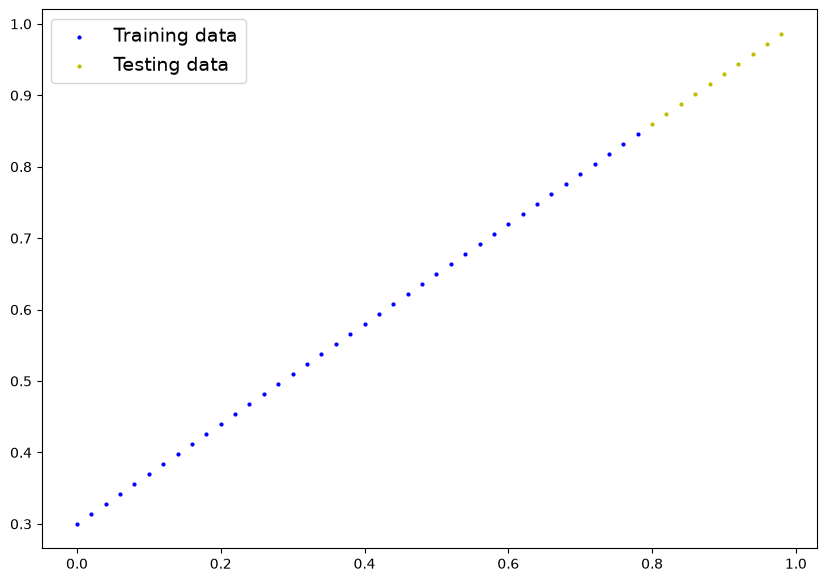

In [125]:
plot_predictions()

### Build the model
Replicating Linear Regression Model using pure PyTorch

In [126]:
#create a linear regression model class
class LinearRegressionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.weights=nn.Parameter(torch.randn(1, #start w random weights, this will get adjusted as the model learns
                                    dtype=torch.float),
                                    requires_grad=True) #we shud update this value by gradient descent, hence true
        self.bias=nn.Parameter(torch.randn(1,dtype=torch.float),requires_grad=True)

    #forward defines the computation in the model
    def forward(self,x:torch.Tensor)->torch.Tensor: #x is the input training/testing data
        return self.weights*x+self.bias




| PyTorch module | What does it do? |
| ----- | ----- |
| [`torch.nn`](https://pytorch.org/docs/stable/nn.html) | Contains all of the building blocks for computational graphs (essentially a series of computations executed in a particular way). |
| [`torch.nn.Parameter`](https://pytorch.org/docs/stable/generated/torch.nn.parameter.Parameter.html#parameter) | Stores tensors that can be used with `nn.Module`. If `requires_grad=True` gradients (used for updating model parameters via [**gradient descent**](https://ml-cheatsheet.readthedocs.io/en/latest/gradient_descent.html))  are calculated automatically, this is often referred to as "autograd".  | 
| [`torch.nn.Module`](https://pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module) | The base class for all neural network modules, all the building blocks for neural networks are subclasses. If you're building a neural network in PyTorch, your models should subclass `nn.Module`. Requires a `forward()` method be implemented. | 
| [`torch.optim`](https://pytorch.org/docs/stable/optim.html) | Contains various optimization algorithms (these tell the model parameters stored in `nn.Parameter` how to best change to improve gradient descent and in turn reduce the loss). | 
| `def forward()` | All `nn.Module` subclasses require a `forward()` method, this defines the computation that will take place on the data passed to the particular `nn.Module` (e.g. the linear regression formula above). |


If the above sounds complex, think of like this, almost everything in a PyTorch neural network comes from `torch.nn`,
* `nn.Module` contains the larger building blocks (layers)
* `nn.Parameter` contains the smaller parameters like weights and biases (put these together to make `nn.Module`(s))
* `forward()` tells the larger blocks how to make calculations on inputs (tensors full of data) within  `nn.Module`(s)
* `torch.optim` contains optimization methods on how to improve the parameters within `nn.Parameter` to better represent input data 

In [127]:
#set manual seel
torch.manual_seed(42)

#create an instance of the model(subclass of nn.Module that contains nn.Parameter)
model_0=LinearRegressionModel()

#check the nn.Parameter within the nn.Module subclass we created
list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [128]:
#get the state of the model
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

#### Making predictions using toch.inference_mode()
To check this we can pass it the test data X_test to see how closely it predicts y_test.

When we pass data to our model, it'll go through the model's forward() method and produce a result using the computation we've defined.

In [129]:
#make predictions
with torch.inference_mode(): #in some version, torch.no_grad()
    y_preds=model_0(X_test)

In [130]:
y_test,y_preds,len(y_test),len(y_preds)

(tensor([[0.8600],
         [0.8740],
         [0.8880],
         [0.9020],
         [0.9160],
         [0.9300],
         [0.9440],
         [0.9580],
         [0.9720],
         [0.9860]]),
 tensor([[0.3982],
         [0.4049],
         [0.4116],
         [0.4184],
         [0.4251],
         [0.4318],
         [0.4386],
         [0.4453],
         [0.4520],
         [0.4588]]),
 10,
 10)

Notice how there's one prediction value per testing sample.

This is because of the kind of data we're using. For our straight line, one X value maps to one y value.

However, machine learning models are very flexible. You could have 100 X values mapping to one, two, three or 10 y values. It all depends on what you're working on.

Our predictions are still numbers on a page, let's visualize them with our plot_predictions() function we created above.

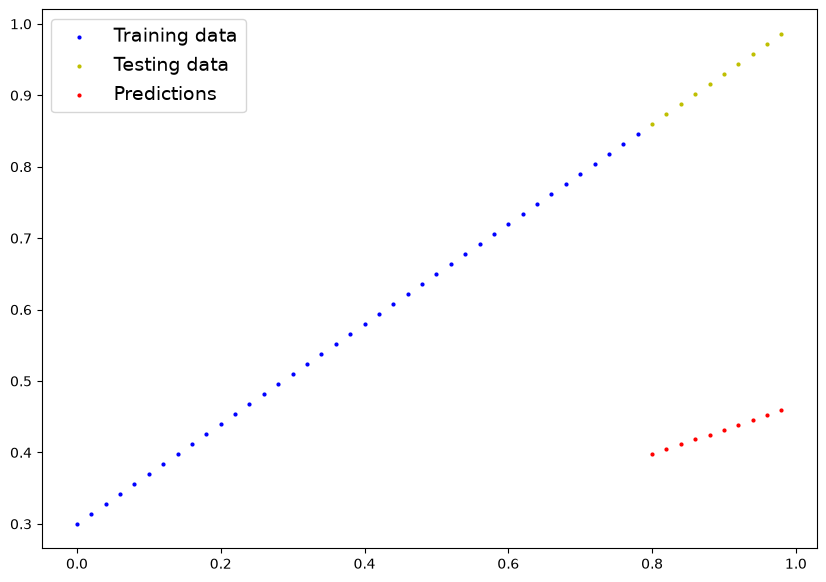

In [131]:
plot_predictions(predictions=y_preds)

In [132]:
y_test-y_preds

tensor([[0.4618],
        [0.4691],
        [0.4764],
        [0.4836],
        [0.4909],
        [0.4982],
        [0.5054],
        [0.5127],
        [0.5200],
        [0.5272]])

This looks bad. These are js random numbers initialized. Now let's start w Training. Wuhoo

### Train Model
Our model is making predictions using random parameters to make calculations- basically guessing (randomly).

Essentially, training means updating the internal paramters, the `weights` and `bias` values to be something that better represents the data.

We could hard code this (since we know the default values weight=0.7 and bias=0.3) but where's the fun in that?

Much of the time you won't know what the ideal parameters are for a model.

Instead, it's much more fun to write code to see if the model can try and figure them out itself.

#### Creating a loss function and optimizer in PyTorch
| Function | What does it do? | Where does it live in PyTorch? | Common values |
| ----- | ----- | ----- | ----- |
| **Loss function** | Measures how wrong your model's predictions (e.g. `y_preds`) are compared to the truth labels (e.g. `y_test`). Lower the better. | PyTorch has plenty of built-in loss functions in [`torch.nn`](https://pytorch.org/docs/stable/nn.html#loss-functions). | Mean absolute error (MAE) for regression problems ([`torch.nn.L1Loss()`](https://pytorch.org/docs/stable/generated/torch.nn.L1Loss.html)). Binary cross entropy for binary classification problems ([`torch.nn.BCELoss()`](https://pytorch.org/docs/stable/generated/torch.nn.BCELoss.html)).  |
| **Optimizer** | Tells your model how to update its internal parameters to best lower the loss. | You can find various optimization function implementations in [`torch.optim`](https://pytorch.org/docs/stable/optim.html). | Stochastic gradient descent ([`torch.optim.SGD()`](https://pytorch.org/docs/stable/generated/torch.optim.SGD.html#torch.optim.SGD)). Adam optimizer ([`torch.optim.Adam()`](https://pytorch.org/docs/stable/generated/torch.optim.Adam.html#torch.optim.Adam)). | 


loss fn- MAE (usually for regression problems where we predict a number)

For our problem, since we're predicting a number, let's use MAE (which is under `torch.nn.L1Loss()`) in PyTorch as our loss function. 

![what MAE loss looks like for our plot data](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01-mae-loss-annotated.png)
*Mean absolute error (MAE, in PyTorch: `torch.nn.L1Loss`) measures the absolute difference between two points (predictions and labels) and then takes the mean across all examples.*

And we'll use SGD, `torch.optim.SGD(params, lr)` where:

* `params` is the target model parameters you'd like to optimize (e.g. the `weights` and `bias` values we randomly set before).
* `lr` is the **learning rate** you'd like the optimizer to update the parameters at, higher means the optimizer will try larger updates (these can sometimes be too large and the optimizer will fail to work), lower means the optimizer will try smaller updates (these can sometimes be too small and the optimizer will take too long to find the ideal values). The learning rate is considered a **hyperparameter** (because it's set by a machine learning engineer). Common starting values for the learning rate are `0.01`, `0.001`, `0.0001`, however, these can also be adjusted over time (this is called [learning rate scheduling](https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate)). 

In [133]:
loss_fn=nn.L1Loss() #MAE is L1
optimizer=torch.optim.SGD(params=model_0.parameters(),lr=0.01)

Now we've got a loss function and an optimizer, it's now time to create a **training loop** (and **testing loop**).

The training loop involves the model going through the training data and learning the relationships between the `features` and `labels`.

The testing loop involves going through the testing data and evaluating how good the patterns are that the model learned on the training data (the model never sees the testing data during training).

Each of these is called a "loop" because we want our model to look (loop through) at each sample in each dataset.

To create these we're going to write a Python `for` loop in the theme of the [unofficial PyTorch optimization loop song](https://twitter.com/mrdbourke/status/1450977868406673410?s=20) (there's a [video version too](https://youtu.be/Nutpusq_AFw)).

![the unofficial pytorch optimization loop song](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01-pytorch-optimization-loop-song.png)
*The unofficial PyTorch optimization loops song, a fun way to remember the steps in a PyTorch training (and testing) loop.*



### PyTorch training loop
For the training loop, we'll build the following steps:

| Number | Step name | What does it do? | Code example |
| ----- | ----- | ----- | ----- |
| 1 | Forward pass | The model goes through all of the training data once, performing its `forward()` function calculations. | `model(x_train)` |
| 2 | Calculate the loss | The model's outputs (predictions) are compared to the ground truth and evaluated to see how wrong they are. | `loss = loss_fn(y_pred, y_train)` | 
| 3 | Zero gradients | The optimizers gradients are set to zero (they are accumulated by default) so they can be recalculated for the specific training step. | `optimizer.zero_grad()` |
| 4 | Perform backpropagation on the loss | Computes the gradient of the loss with respect for every model parameter to be updated  (each parameter with `requires_grad=True`). This is known as **backpropagation**, hence "backwards".  | `loss.backward()` |
| 5 | Update the optimizer (**gradient descent**) | Update the parameters with `requires_grad=True` with respect to the loss gradients in order to improve them. | `optimizer.step()` |

![pytorch training loop annotated](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01-pytorch-training-loop-annotated.png)

> **Note:** The above is just one example of how the steps could be ordered or described. With experience you'll find making PyTorch training loops can be quite flexible.
>
> And on the ordering of things, the above is a good default order but you may see slightly different orders. Some rules of thumb: 
> * Calculate the loss (`loss = ...`) *before* performing backpropagation on it (`loss.backward()`).
> * Zero gradients (`optimizer.zero_grad()`) *before* computing the gradients of the loss with respect to every model parameter (`loss.backward()`).
> * Step the optimizer (`optimizer.step()`) *after* performing backpropagation on the loss (`loss.backward()`).

For resources to help understand what's happening behind the scenes with backpropagation and gradient descent, see the extra-curriculum section.


In [134]:
torch.manual_seed(42)

#set the number of epochs
epochs=250

train_loss_values=[]
test_loss_values=[]
epoch_count=[]
test_preds=[]

for epoch in range(epochs):
    model_0.train()
    y_pred=model_0(X_train)
    # print(y_pred)
    loss=loss_fn(y_pred,y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    model_0.eval()
    with torch.inference_mode():
        test_pred=model_0(X_test)
        test_loss=loss_fn(test_pred,y_test.type(torch.float))
        test_preds.append(test_pred)

        if epoch%10==0:
            epoch_count.append(epoch)
            train_loss_values.append(loss.detach().numpy())
            test_loss_values.append(test_loss.detach().numpy())
            
            print(f"Epoch {epoch} | MAE Train loss; {loss} | MAE Test loss: {test_loss}")

Epoch 0 | MAE Train loss; 0.31288138031959534 | MAE Test loss: 0.48106518387794495
Epoch 10 | MAE Train loss; 0.1976713240146637 | MAE Test loss: 0.3463551998138428
Epoch 20 | MAE Train loss; 0.08908725529909134 | MAE Test loss: 0.21729660034179688
Epoch 30 | MAE Train loss; 0.053148526698350906 | MAE Test loss: 0.14464017748832703
Epoch 40 | MAE Train loss; 0.04543796554207802 | MAE Test loss: 0.11360953003168106
Epoch 50 | MAE Train loss; 0.04167863354086876 | MAE Test loss: 0.09919948130846024
Epoch 60 | MAE Train loss; 0.03818932920694351 | MAE Test loss: 0.08886633068323135
Epoch 70 | MAE Train loss; 0.03476089984178543 | MAE Test loss: 0.0805937647819519
Epoch 80 | MAE Train loss; 0.03132382780313492 | MAE Test loss: 0.07232122868299484
Epoch 90 | MAE Train loss; 0.02788739837706089 | MAE Test loss: 0.06473556160926819
Epoch 100 | MAE Train loss; 0.024458957836031914 | MAE Test loss: 0.05646304413676262
Epoch 110 | MAE Train loss; 0.021020207554101944 | MAE Test loss: 0.048190496

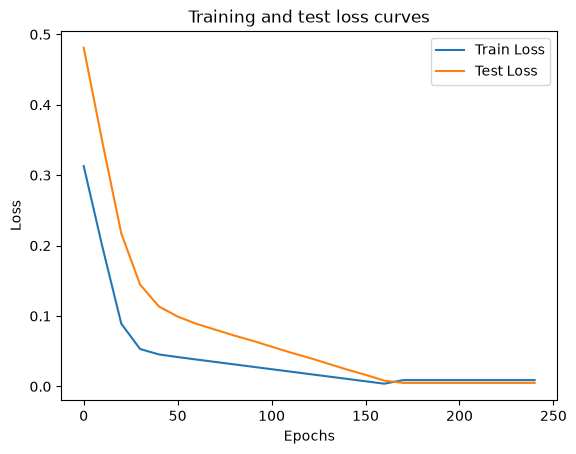

In [135]:
#plot the loss curves
plt.plot(epoch_count,train_loss_values,label="Train Loss")
plt.plot(epoch_count,test_loss_values,label="Test Loss")
plt.title("Training and test loss curves")
plt.ylabel("Loss")
plt.xlabel("Epochs")
plt.legend()

But why did the loss go down?

Well, thanks to our loss function and optimizer, the model's internal parameters (weights and bias) were updated to better reflect the underlying patterns in the data.

Let's inspect our model's .state_dict() to see how close our model gets to the original values we set for weights and bias.

In [136]:
#find out model's learned parameters
print(model_0.state_dict())
print(weight,bias)

OrderedDict([('weights', tensor([0.6990])), ('bias', tensor([0.3093]))])
0.7 0.3


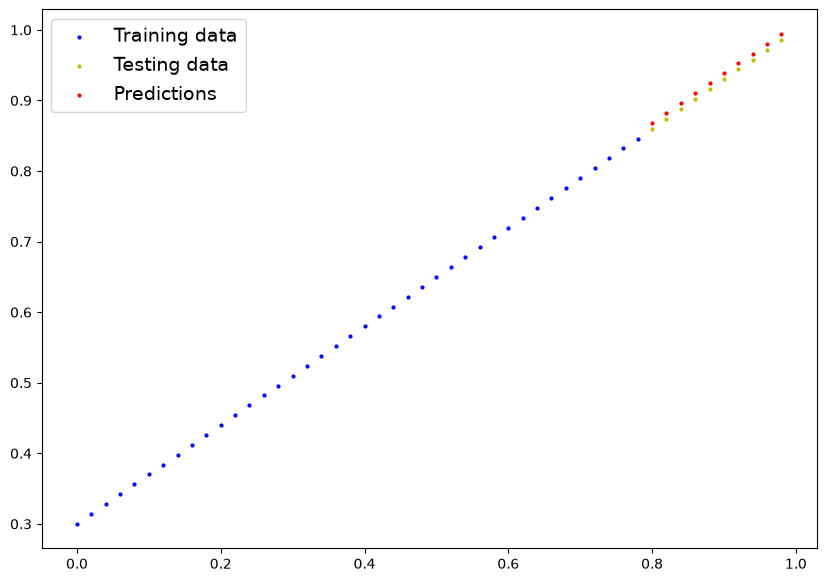

In [137]:
plot_predictions(predictions=test_preds[-1])

### Making predictions with a trained PyTorch model - Inference
1. Set the model in evaluation mode (`model.eval()`).
2. Make the predictions using the inference mode context manager (`with torch.inference_mode(): ...`).
3. All predictions should be made with objects on the same device (e.g. data and model on GPU only or data and model on CPU only).

In [138]:
model_0.eval()
with torch.inference_mode():
    y_preds=model_0(X_test)
y_preds,y_test

(tensor([[0.8685],
         [0.8825],
         [0.8965],
         [0.9105],
         [0.9245],
         [0.9384],
         [0.9524],
         [0.9664],
         [0.9804],
         [0.9944]]),
 tensor([[0.8600],
         [0.8740],
         [0.8880],
         [0.9020],
         [0.9160],
         [0.9300],
         [0.9440],
         [0.9580],
         [0.9720],
         [0.9860]]))

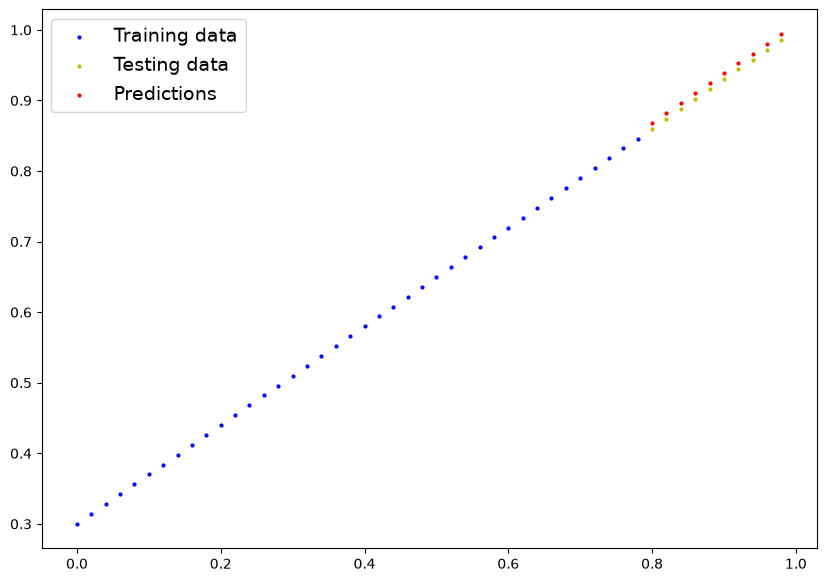

In [139]:
plot_predictions(predictions=y_preds)

### 5. Saving and loading a PyTorch model

If you've trained a PyTorch model, chances are you'll want to save it and export it somewhere.

As in, you might train it on Google Colab or your local machine with a GPU but you'd like to now export it to some sort of application where others can use it. 

Or maybe you'd like to save your progress on a model and come back and load it back later.

For saving and loading models in PyTorch, there are three main methods you should be aware of (all of below have been taken from the [PyTorch saving and loading models guide](https://pytorch.org/tutorials/beginner/saving_loading_models.html#saving-loading-model-for-inference)):

| PyTorch method | What does it do? | 
| ----- | ----- |
| [`torch.save`](https://pytorch.org/docs/stable/torch.html?highlight=save#torch.save) | Saves a serialized object to disk using Python's [`pickle`](https://docs.python.org/3/library/pickle.html) utility. Models, tensors and various other Python objects like dictionaries can be saved using `torch.save`.  | 
| [`torch.load`](https://pytorch.org/docs/stable/torch.html?highlight=torch%20load#torch.load) | Uses `pickle`'s unpickling features to deserialize and load pickled Python object files (like models, tensors or dictionaries) into memory. You can also set which device to load the object to (CPU, GPU etc). |
| [`torch.nn.Module.load_state_dict`](https://pytorch.org/docs/stable/generated/torch.nn.Module.html?highlight=load_state_dict#torch.nn.Module.load_state_dict)| Loads a model's parameter dictionary (`model.state_dict()`) using a saved `state_dict()` object. | 

> **Note:** As stated in [Python's `pickle` documentation](https://docs.python.org/3/library/pickle.html), the `pickle` module **is not secure**. That means you should only ever unpickle (load) data you trust. That goes for loading PyTorch models as well. Only ever use saved PyTorch models from sources you trust.


In [140]:
from pathlib import Path

#create models directory
MODEL_PATH=Path("models")
MODEL_PATH.mkdir(parents=True,exist_ok=True)

#create model save path
MODEL_NAME="pytorch_workflow_model.pth"
MODEL_SAVE_PATH=MODEL_PATH/MODEL_NAME

#save the model state dict
print(f"Saving Model to {MODEL_SAVE_PATH}")
torch.save(obj=model_0.state_dict(), #only saving the state_dict() only saves the model's learned paramters
            f=MODEL_SAVE_PATH)

Saving Model to models\pytorch_workflow_model.pth


In [141]:
#check the saved file path
from pathlib import Path

path = Path("models/pytorch_workflow_model.pth")

print(path.exists())

True


Why call torch.load() inside torch.nn.Module.load_state_dict()?

Because we only saved the model's state_dict() which is a dictionary of learned parameters and not the entire model, we first have to load the state_dict() with torch.load() and then pass that state_dict() to a new instance of our model (which is a subclass of nn.Module).

Why not save the entire model?

Saving the entire model rather than just the state_dict() is more intuitive, however, to quote the PyTorch documentation (italics mine):

The disadvantage of this approach (saving the whole model) is that the serialized data is bound to the specific classes and the exact directory structure used when the model is saved...

Because of this, your code can break in various ways when used in other projects or after refactors.

So instead, we're using the flexible method of saving and loading just the state_dict(), which again is basically a dictionary of model parameters.

Let's test it out by creating another instance of LinearRegressionModel(), which is a subclass of torch.nn.Module and will hence have the in-built method load_state_dict().

In [142]:
#instantiate a new instance of our model (this will be instantiated w random weights)

#to load from different files:
#from pytorch_workflow import LinearRegressionModel 
#feasible only for .py files, not .ipynb. hence, save the LinearRegressionModel class to a py file.
loaded_model_0=LinearRegressionModel()

loaded_model_0.load_state_dict(torch.load(f=MODEL_SAVE_PATH))


<All keys matched successfully>

In [143]:
#instantiate a new instance of our model (this will be instantiated w random weights)

import importlib
import model
import torch
importlib.reload(model)

from model import LinearRegressionModel
loaded_model_0=LinearRegressionModel()
MODEL_SAVE_PATH='models\pytorch_workflow_model.pth'
loaded_model_0.load_state_dict(torch.load(f=MODEL_SAVE_PATH))

<All keys matched successfully>

In [144]:
loaded_model_0.eval()
with torch.inference_mode():
    loaded_model_preds=loaded_model_0(X_test)

y_preds==loaded_model_preds

tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]])

Hence, our model is saving nad loading as expected as it matches with the previous model predictions.

## Putting it all together

In [145]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.__version__

'2.13.0+cpu'

In [146]:
device="cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [147]:
weight=0.7
bias=0.3

start=0
end=1
step=0.02

X=torch.arange(start,end,step).unsqueeze(dim=1)
y=weight*X+bias
X[:10],y[:10]

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

In [148]:
train_test_split=int(0.8*len(X))
X_train,y_train=X[:train_test_split],y[:train_test_split]
X_test,y_test=X[train_test_split:],y[train_test_split:]

len(X_test),len(y_test)

(10, 10)

In [149]:
def plot_prediction(train_data=X_train,train_label=y_train,test_data=X_test,test_label=y_test,predictions=None):
    plt.figure(figsize=(10,7))
    plt.scatter(train_data,train_label,c="b",s=4,label="Training Data")
    plt.scatter(test_data,test_label,c="y",s=4,label="Testing Data")
    if predictions is not None:
        plt.scatter(test_label,predictions,c="r",s=4,label="Predictions")
    plt.legend()

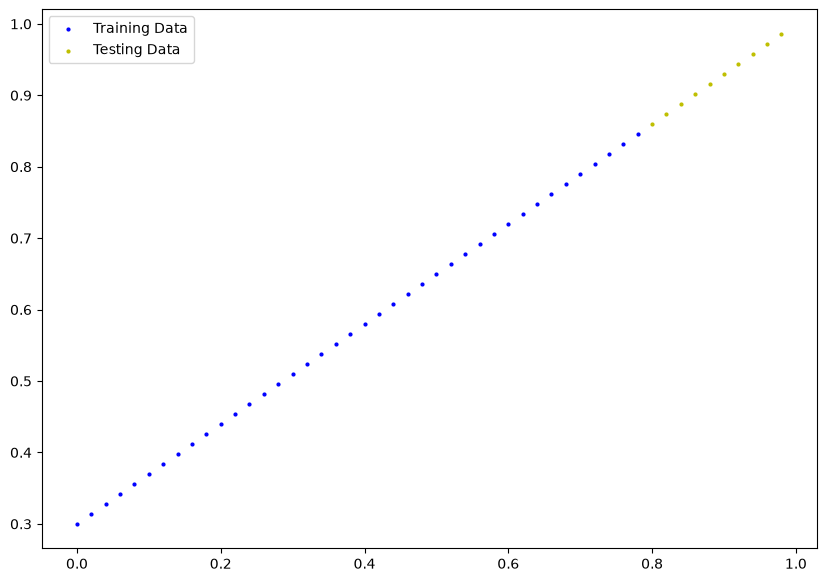

In [150]:
plot_prediction(X_train,y_train,X_test,y_test)

In [151]:
class LinearRegressionModelV2(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear_layer=nn.Linear(in_features=1,out_features=1)
        #Linear class internally does this
        # self.weights=nn.Parameter(torch.randn(1,dtype=torch.float),requires_grad=True)
        # self.bias=nn.Parameter(torch.randn(1,dtype=torch.float),requires_grad=True)

    def forward(self,x:torch.Tensor)->torch.Tensor:
        return self.linear_layer(x)
        #return self.weights*x+self.bias

torch.manual_seed(42)
model_1=LinearRegressionModelV2()
model_1,model_1.state_dict()
    

(LinearRegressionModelV2(
   (linear_layer): Linear(in_features=1, out_features=1, bias=True)
 ),
 OrderedDict([('linear_layer.weight', tensor([[0.7645]])),
              ('linear_layer.bias', tensor([0.8300]))]))

In [152]:
next(model_1.parameters()).device

device(type='cpu')

In [153]:
device="gpu" if torch.cuda.is_available() else "cpu"
model_1.to(device)
next(model_1.parameters()).device

device(type='cpu')

In [154]:
loss_fn=nn.L1Loss()
optimizer=torch.optim.SGD(params=model_1.parameters(),lr=0.01)
loss_fn,optimizer

(L1Loss(),
 SGD (
 Parameter Group 0
     dampening: 0
     differentiable: False
     foreach: None
     fused: None
     lr: 0.01
     maximize: False
     momentum: 0
     nesterov: False
     weight_decay: 0
 ))

In [155]:
torch.manual_seed(42)
epochs=2000
train_loss_val=[]
test_loss_val=[]
test_preds=[]
epoch_count=[]

for epoch in range(epochs):
    model_1.train()
    y_pred=model_1(X_train)
    loss=loss_fn(y_pred,y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    model_1.eval()
    with torch.inference_mode():
        test_pred=model_1(X_test)
        test_loss=loss_fn(test_pred,y_test)
    if epoch%100==0:
        epoch_count.append(epoch)
        train_loss_val.append(loss.detach().numpy())
        test_loss_val.append(test_loss.detach().numpy())
        test_preds.append(test_pred)

        print(f"Epoch:{epoch} | MAE Train Loss:{loss} | MAE Test Loss:{test_loss}")

Epoch:0 | MAE Train Loss:0.5551779866218567 | MAE Test Loss:0.5739762187004089
Epoch:100 | MAE Train Loss:0.006215679459273815 | MAE Test Loss:0.014086711220443249
Epoch:200 | MAE Train Loss:0.0012645035749301314 | MAE Test Loss:0.013801807537674904
Epoch:300 | MAE Train Loss:0.0012645035749301314 | MAE Test Loss:0.013801807537674904
Epoch:400 | MAE Train Loss:0.0012645035749301314 | MAE Test Loss:0.013801807537674904
Epoch:500 | MAE Train Loss:0.0012645035749301314 | MAE Test Loss:0.013801807537674904
Epoch:600 | MAE Train Loss:0.0012645035749301314 | MAE Test Loss:0.013801807537674904
Epoch:700 | MAE Train Loss:0.0012645035749301314 | MAE Test Loss:0.013801807537674904
Epoch:800 | MAE Train Loss:0.0012645035749301314 | MAE Test Loss:0.013801807537674904
Epoch:900 | MAE Train Loss:0.0012645035749301314 | MAE Test Loss:0.013801807537674904
Epoch:1000 | MAE Train Loss:0.0012645035749301314 | MAE Test Loss:0.013801807537674904
Epoch:1100 | MAE Train Loss:0.0012645035749301314 | MAE Test 

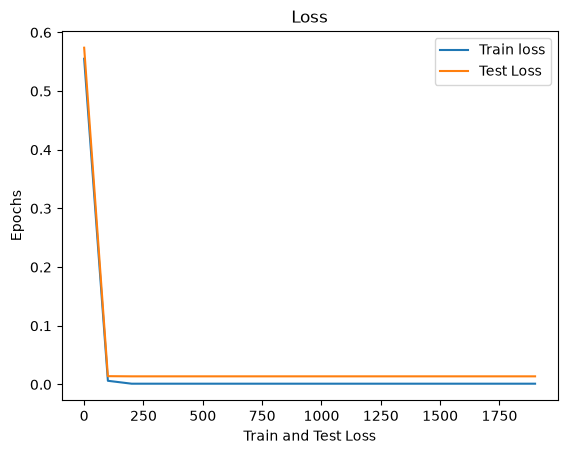

In [156]:
import matplotlib.pyplot as plt
plt.plot(epoch_count,train_loss_val,label="Train loss")
plt.plot(epoch_count,test_loss_val,label="Test Loss")
plt.xlabel("Train and Test Loss")
plt.ylabel("Epochs")
plt.title("Loss")
plt.legend()

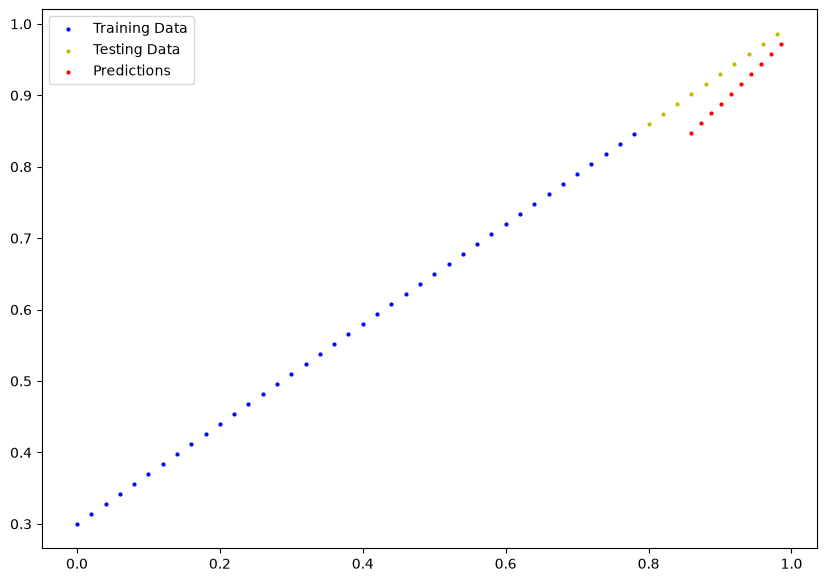

In [157]:
plot_prediction(predictions=test_preds[-1])

In [158]:
from pprint import pprint
pprint(model_1.state_dict())
print(weight,bias)

OrderedDict([('linear_layer.weight', tensor([[0.6968]])),
             ('linear_layer.bias', tensor([0.3025]))])
0.7 0.3


In [166]:
#make predictions
model_1.eval()
with torch.inference_mode():
    y_preds=model_1(X_test)
y_preds,y_test

(tensor([[0.8600],
         [0.8739],
         [0.8878],
         [0.9018],
         [0.9157],
         [0.9296],
         [0.9436],
         [0.9575],
         [0.9714],
         [0.9854]]),
 tensor([[0.8600],
         [0.8740],
         [0.8880],
         [0.9020],
         [0.9160],
         [0.9300],
         [0.9440],
         [0.9580],
         [0.9720],
         [0.9860]]))

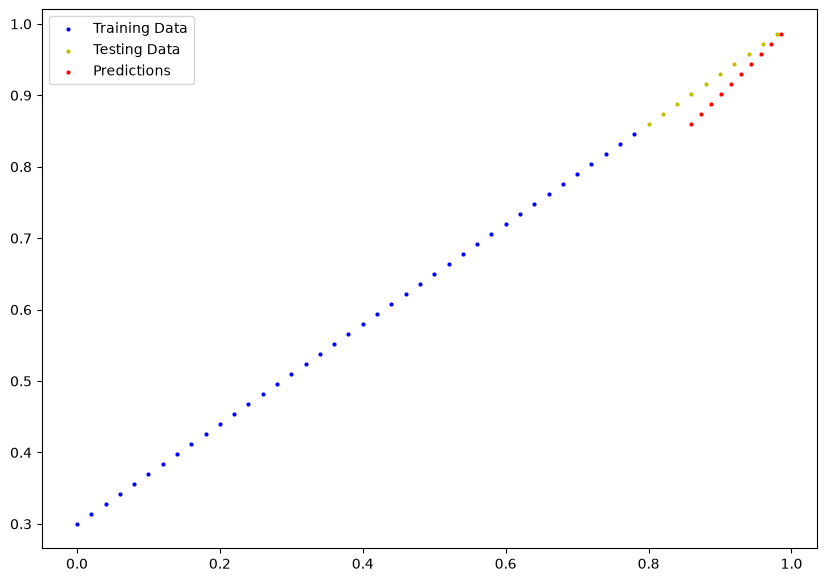

In [168]:
plot_prediction(predictions=y_preds)

In [169]:
from pathlib import Path
MODEL_PATH=Path("models")
MODEL_PATH.mkdir(parents=True,exist_ok=True)

MODEL_NAME="pytorch_workflow_model_2"
MODEL_SAVE_PATH=MODEL_PATH/MODEL_NAME

print(f"Saving model to {MODEL_SAVE_PATH}")
torch.save(obj=model_1.state_dict(),f=MODEL_SAVE_PATH)

Saving model to models\pytorch_workflow_model_2


In [172]:
loaded_model_1=LinearRegressionModelV2()
loaded_model_1.load_state_dict(torch.load(MODEL_SAVE_PATH))

loaded_model_1.to(device)
print(f"Loaded Model:\n{loaded_model_1}")
print(next(loaded_model_1.parameters()).device)

Loaded Model:
LinearRegressionModelV2(
  (linear_layer): Linear(in_features=1, out_features=1, bias=True)
)
cpu


In [173]:
loaded_model_1.eval()
with torch.inference_mode():
    loaded_model_1_preds=loaded_model_1(X_test)
loaded_model_1_preds==y_preds

tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]])

## PRACTICE

In [ ]:
#Create a straight line dataset using the linear regression formula (weight * X + bias).
start=1
end=51
step=0.5
weights=0.3
bias=0.9
X=torch.arange(start,end,step)
y=weights*X+bias
len(X)
training_split=int(0.8*len(X))
X_train,y_train=X[:training_split],y[:training_split]
X_test,y_test=X[training_split:],y[training_split:]

def plot_prediction(train_label=y_train,train_data=X_train,test_label=y_test,test_data=X_test,predictions=None):
    plt.figure(figsize=(10,7))
    plt.scatter(train_data,train_label,c="b",s=4,label="Training")
    plt.scatter(test_data,test_label,c="o",s=4,label="Testing")
    if predictions is not None:
        plt.scatter(test_label,predictions,c="r",s=4,label="Predictions")
    plt.legend()


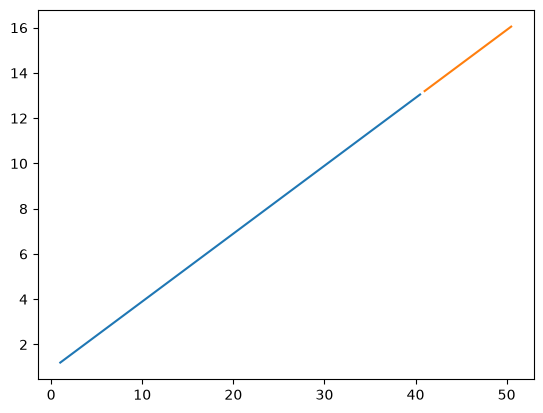

In [188]:
plt.plot(X_train,y_train,X_test,y_test)

In [189]:
class LinearRegressionModelV3(nn.Module):
    def __init__(self):
        super().__init__()
        self.weights=nn.Parameter(torch.randn(1,dtype=torch.float),requires_grad=True)
        self.bias=nn.Parameter(torch.randn(1,dtype=torch.float),requires_grad=True)
        #self.linear_layer=nn.Linear(in_features=1,out_features=2)
    def forward(self,x:torch.Tensor)->torch.Tensor:
        return self.weights*x+self.bias
        #return self.linear_layer(x)
torch.manual_seed(42)
model_2=LinearRegressionModelV2()
model_2,model_2.state_dict()


(LinearRegressionModelV2(
   (linear_layer): Linear(in_features=1, out_features=1, bias=True)
 ),
 OrderedDict([('linear_layer.weight', tensor([[0.7645]])),
              ('linear_layer.bias', tensor([0.8300]))]))

In [191]:
loss_fn=nn.L1Loss()
optimizer=torch.optim.SGD(params=model_2.parameters(),lr=0.01)

epoch_count=[]
train_loss_values=[]
test_loss_values=[]
test_preds=[]
epochs=300

for epoch in range(epochs):
    model_2.train()
    y_pred=model_2(X_train)
    loss=loss_fn(y_pred,y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    if epoch%20==0:
        model_2.eval()
        with torch.inference_mode():
            test_pred=model_2(X_test)
            test_loss=loss_fn(test_pred,y_test)
            
        epoch_count.append(epoch)
        train_loss_values(loss.detach().numpy())
        test_loss_values(test_loss.detach().numpy())
        test_preds.append(test_pred)
        print(f"Epoch:{epoch} | MAE Train Loss:{loss} | MAE Test Loss:{test_loss}")
    


RuntimeError: mat1 and mat2 shapes cannot be multiplied (1x80 and 1x1)